# Proyecto 2 - Clasificación de diabetes con indicadores de salud del CDC
Fabian Prado 

Sofia Lopez

## Configuración

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
SEMILLA = 42

# Funciona tanto desde la raíz del repo como desde notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DATOS = RAIZ / "data" / "raw" / "diabetes_012_health_indicators_BRFSS2015.csv.zip"
RUTA_PARTICION = RAIZ / "data" / "processed" / "particion.csv"

OBJETIVO = "Diabetes_012"
NOMBRES_CLASE = {0: "Sin diabetes", 1: "Prediabetes", 2: "Diabetes"}
COLORES = ["#86b6ef", "#2a78d6", "#104281"]  # de claro a oscuro según severidad

### Fuente

CDC Diabetes Health Indicators de UCI ML Repository #891 (https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators)

Archivo usado: `diabetes_012_health_indicators_BRFSS2015.csv` de [Kaggle](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset), 

**Nota:** el CSV de UCI solo tiene una etiqueta binaria (diabetes sí/no) y deja a las personas con prediabetes en la clase "sin diabetes". Por eso usamos el archivo de Kaggle, que tiene los mismos 253,680 registros y las mismas 21 variables pero con la etiqueta de tres clases que necesitamos. Lo comprobamos comparando ambos archivos.

### Variable objetivo: Diabetes_012

| Valor | Clase | Significado |
|---|---|---|
| 0 | Sin diabetes | No tiene diabetes, o solo la tuvo durante el embarazo |
| 1 | Prediabetes | Le dijeron que tiene prediabetes |
| 2 | Diabetes | Le diagnosticaron diabetes |

Es un **diagnóstico reportado por la misma persona** en la encuesta: alguien con diabetes que no ha sido diagnosticado aparece como clase 0.

### 1.5 Diccionario de variables

| Variable | Descripción | Tipo | Valores |
|---|---|---|---|
| HighBP | Tiene presión arterial alta | Binaria | 0 = no, 1 = sí |
| HighChol | Tiene colesterol alto | Binaria | 0 = no, 1 = sí |
| CholCheck | Se revisó el colesterol en los últimos 5 años | Binaria | 0 = no, 1 = sí |
| BMI | Índice de masa corporal | Numérica | entero |
| Smoker | Ha fumado al menos 100 cigarrillos en su vida | Binaria | 0 = no, 1 = sí |
| Stroke | Ha tenido un derrame cerebral | Binaria | 0 = no, 1 = sí |
| HeartDiseaseorAttack | Enfermedad coronaria o infarto | Binaria | 0 = no, 1 = sí |
| PhysActivity | Actividad física en los últimos 30 días | Binaria | 0 = no, 1 = sí |
| Fruits | Come fruta al menos 1 vez al día | Binaria | 0 = no, 1 = sí |
| Veggies | Come verduras al menos 1 vez al día | Binaria | 0 = no, 1 = sí |
| HvyAlcoholConsump | Consumo excesivo de alcohol | Binaria | 0 = no, 1 = sí |
| AnyHealthcare | Tiene seguro o cobertura médica | Binaria | 0 = no, 1 = sí |
| NoDocbcCost | No pudo ir al médico por el costo (último año) | Binaria | 0 = no, 1 = sí |
| GenHlth | Percepción de su salud general | Ordinal | 1 = excelente ... 5 = mala |
| MentHlth | Días con mala salud mental (últimos 30) | Numérica | 0 a 30 |
| PhysHlth | Días con mala salud física (últimos 30) | Numérica | 0 a 30 |
| DiffWalk | Dificultad para caminar o subir gradas | Binaria | 0 = no, 1 = sí |
| Sex | Sexo | Binaria | 0 = mujer, 1 = hombre |
| Age | Grupo de edad | Ordinal | 1 = 18-24 ... 13 = 80 o más |
| Education | Nivel educativo | Ordinal | 1 = ninguno ... 6 = universidad completa |
| Income | Ingreso anual del hogar | Ordinal | 1 = menos de $10k ... 8 = $75k o más |


### Carga de datos y tamaño

In [3]:
df = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df.shape[0]:,}   Columnas: {df.shape[1]}  (21 predictoras + 1 objetivo)")
df.head()

Filas: 253,680   Columnas: 22  (21 predictoras + 1 objetivo)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 2. Análisis exploratorio

### Tipos de datos

In [4]:
df.dtypes.value_counts()

float64    22
Name: count, dtype: int64

Todas las columnas son `float64`, pero solo contienen números enteros (son respuestas codificadas de la encuesta). **Decisión:** convertirlas a `int`.

In [5]:
df = df.astype(int)

### Valores faltantes

In [6]:
print("Valores faltantes:", df.isna().sum().sum())

Valores faltantes: 0


No hay valores faltantes.

### Valores fuera de rango

In [7]:
df.describe().T[["min", "max"]]

,min,max
Diabetes_012,0.0,2.0
HighBP,0.0,1.0
HighChol,0.0,1.0
CholCheck,0.0,1.0
BMI,12.0,98.0
Smoker,0.0,1.0
Stroke,0.0,1.0
HeartDiseaseorAttack,0.0,1.0
PhysActivity,0.0,1.0
Fruits,0.0,1.0


Todos los valores están dentro de los rangos del diccionario. La única variable sin un rango fijo es `BMI`, que va de 12 a 98.

### Registros duplicados

In [8]:
duplicados = df.duplicated()
print(f"Filas duplicadas: {duplicados.sum():,} ({duplicados.mean():.1%})")
df[duplicados][OBJETIVO].value_counts().rename(index=NOMBRES_CLASE)

Filas duplicadas: 23,899 (9.4%)


Diabetes_012
Sin diabetes    23648
Diabetes          249
Prediabetes         2
Name: count, dtype: int64

Hay unas 24 mil filas repetidas, casi todas de personas sin diabetes. Como la mayoría de variables son de sí/no, es normal que varias personas distintas den exactamente las mismas respuestas. **Decisión:** conservarlas, porque probablemente son personas diferentes y no errores.

### División en entrenamiento y prueba

Separamos el 20% de los datos para prueba antes de analizar patrones, para que el test se use una sola vez al final. Guardamos la división en `data/processed/particion.csv`.

In [9]:
train, test = train_test_split(df, test_size=0.2, stratify=df[OBJETIVO], random_state=SEMILLA)

RUTA_PARTICION.parent.mkdir(parents=True, exist_ok=True)
particion = pd.Series("train", index=df.index, name="conjunto")
particion[test.index] = "test"
particion.rename_axis("indice").to_csv(RUTA_PARTICION)

print(f"Entrenamiento: {len(train):,} filas   Prueba: {len(test):,} filas")

Entrenamiento: 202,944 filas   Prueba: 50,736 filas


A partir de aquí el análisis se hace solo con el conjunto de entrenamiento.

### Distribución de la variable objetivo

              registros     %
Diabetes_012                 
Sin diabetes     170962  84.2
Prediabetes        3705   1.8
Diabetes          28277  13.9


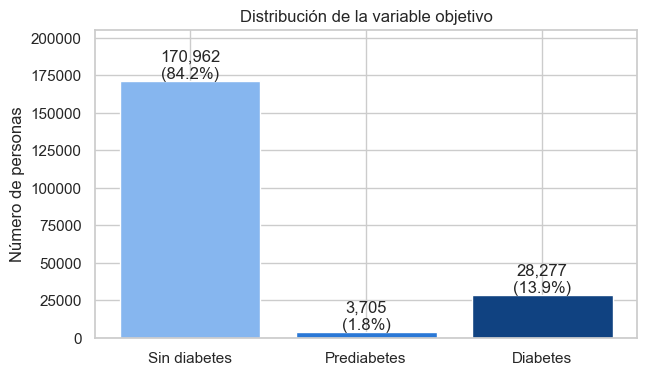

In [10]:
conteo = train[OBJETIVO].value_counts().sort_index()
porcentaje = (conteo / conteo.sum() * 100).round(1)
print(pd.DataFrame({"registros": conteo, "%": porcentaje}).rename(index=NOMBRES_CLASE))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(NOMBRES_CLASE.values(), conteo, color=COLORES)
for i, (n, p) in enumerate(zip(conteo, porcentaje)):
    ax.text(i, n, f"{n:,}\n({p}%)", ha="center", va="bottom")
ax.set_ylim(0, conteo.max() * 1.2)
ax.set_ylabel("Número de personas")
ax.set_title("Distribución de la variable objetivo")
plt.show()

**Qué muestra:** cuántas personas hay en cada clase.

**Patrón:** las clases están muy desbalanceadas. El 84% no tiene diabetes, el 14% tiene diabetes y solo el 1.8% tiene prediabetes.

**Decisión:**
- Usar F1-score macro como métrica principal. Un modelo que siempre diga "sin diabetes" tendría 84% de accuracy, pero no detectaría a nadie enfermo.
- Usar class_weight="balanced" en los modelos, para que los errores en las clases pequeñas pesen más.
- Usar división y validación cruzada estratificadas.

### Outliers: índice de masa corporal por clase

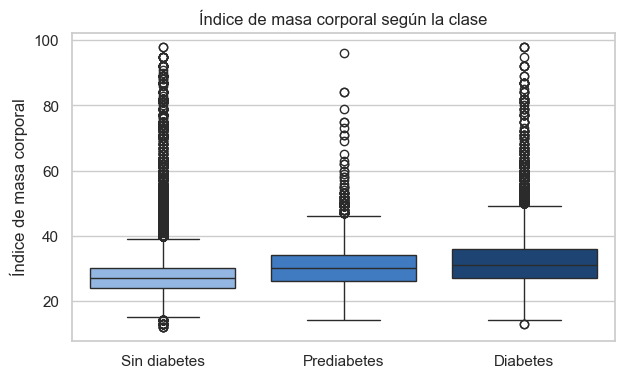

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,,,,,,,,
Sin diabetes,170962.0,27.7,6.3,12.0,24.0,27.0,30.0,98.0
Prediabetes,3705.0,30.7,6.9,14.0,26.0,30.0,34.0,96.0
Diabetes,28277.0,32.0,7.4,13.0,27.0,31.0,36.0,98.0


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=train, x=OBJETIVO, y="BMI", hue=OBJETIVO, palette=COLORES, legend=False, ax=ax)
ax.set_xticks([0, 1, 2], NOMBRES_CLASE.values())
ax.set_xlabel("")
ax.set_ylabel("Índice de masa corporal")
ax.set_title("Índice de masa corporal según la clase")
plt.show()

train.groupby(OBJETIVO)["BMI"].describe().rename(index=NOMBRES_CLASE).round(1)

**Qué muestra:** la distribución del índice de masa corporal (IMC) en cada clase. Los puntos son valores atípicos.

**Patrón:**
- El IMC sube con la enfermedad: la mediana es 27 en personas sin diabetes, 30 en prediabetes y 31 en diabetes.
- Las cajas de prediabetes y diabetes se parecen mucho, así que el IMC ayuda a separar a las personas sanas, pero no tanto a distinguir prediabetes de diabetes.
- Hay valores muy altos (hasta 98), pero son pocos.

**Decisión:** **conservar los outliers**. No podemos saber si son errores o casos reales de obesidad severa, y muchos de ellos tienen diabetes, así que aportan información. Los árboles no se ven afectados por valores extremos; para la regresión logística escalaremos los datos.

### Correlación de las variables

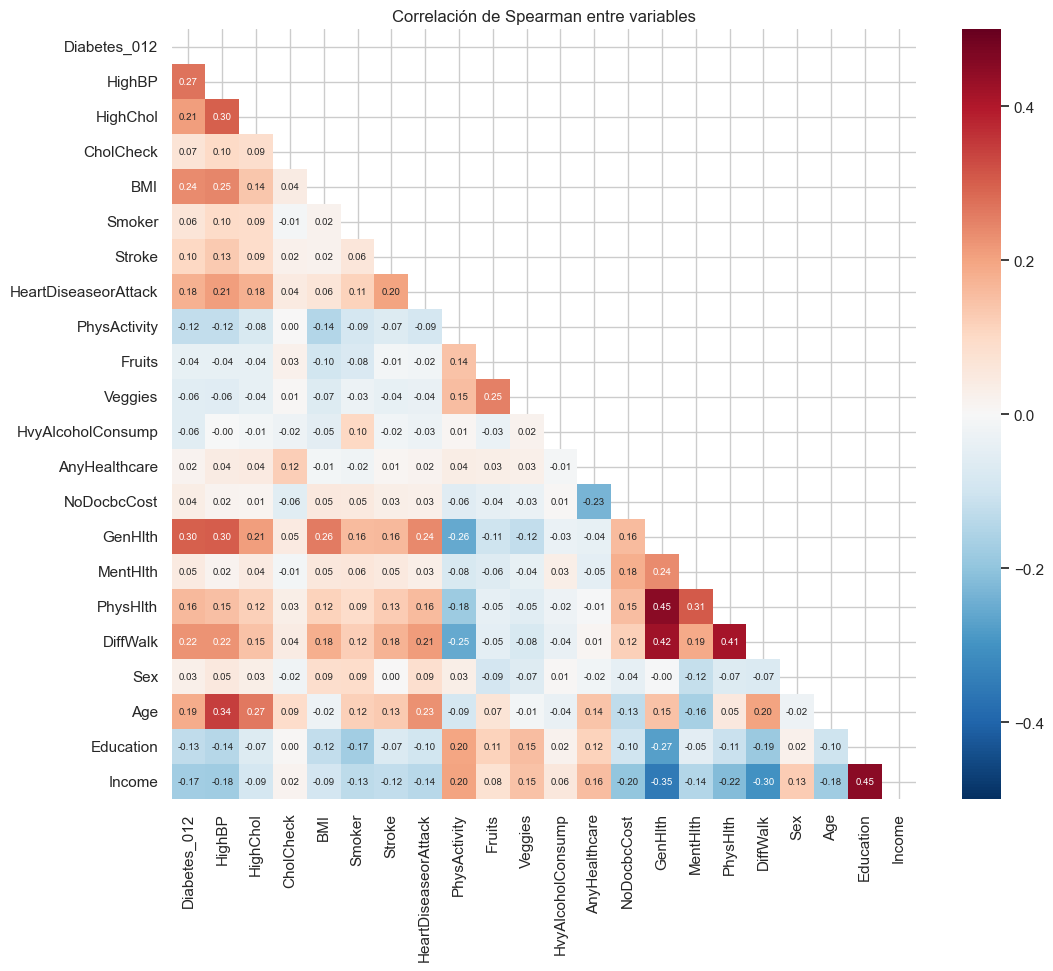

Correlación con la variable objetivo:


GenHlth                 0.30
HighBP                  0.27
BMI                     0.24
DiffWalk                0.22
HighChol                0.21
Age                     0.19
HeartDiseaseorAttack    0.18
PhysHlth                0.16
Stroke                  0.10
CholCheck               0.07
Smoker                  0.06
MentHlth                0.05
NoDocbcCost             0.04
Sex                     0.03
AnyHealthcare           0.02
Fruits                 -0.04
HvyAlcoholConsump      -0.06
Veggies                -0.06
PhysActivity           -0.12
Education              -0.13
Income                 -0.17
Name: Diabetes_012, dtype: float64

In [12]:
correlacion = train.corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
mascara = np.triu(np.ones_like(correlacion, dtype=bool))
sns.heatmap(correlacion, mask=mascara, cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5,
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlación de Spearman entre variables")
plt.show()

print("Correlación con la variable objetivo:")
correlacion[OBJETIVO].drop(OBJETIVO).sort_values(ascending=False).round(2)

Usamos la correlación de Spearman porque la mayoría de variables son binarias u ordinales.

**Qué muestra:** qué tan relacionadas están las variables entre sí y con la diabetes (primera columna).

**Patrón:**
- Las variables más relacionadas con la diabetes son: salud general (`GenHlth`), presión alta (`HighBP`), IMC (`BMI`), dificultad para caminar (`DiffWalk`), colesterol alto (`HighChol`) y edad (`Age`).
- Ingreso, educación y actividad física tienen correlación negativa: a mayor valor, menos diabetes.
- Ninguna correlación es muy alta (todas menores a 0.5), así que **ninguna variable sola** basta para predecir la clase.

**Decisión:** conservar las 21 variables. No hay variables tan parecidas entre sí como para eliminar alguna, y el modelo necesita combinar varias señales débiles. Las variables `GenHlth`, `Age`, `Education`, `Income` se dejan como números porque su orden tiene significado, así que no aplicamos one-hot encoding.

### Factores de riesgo por clase

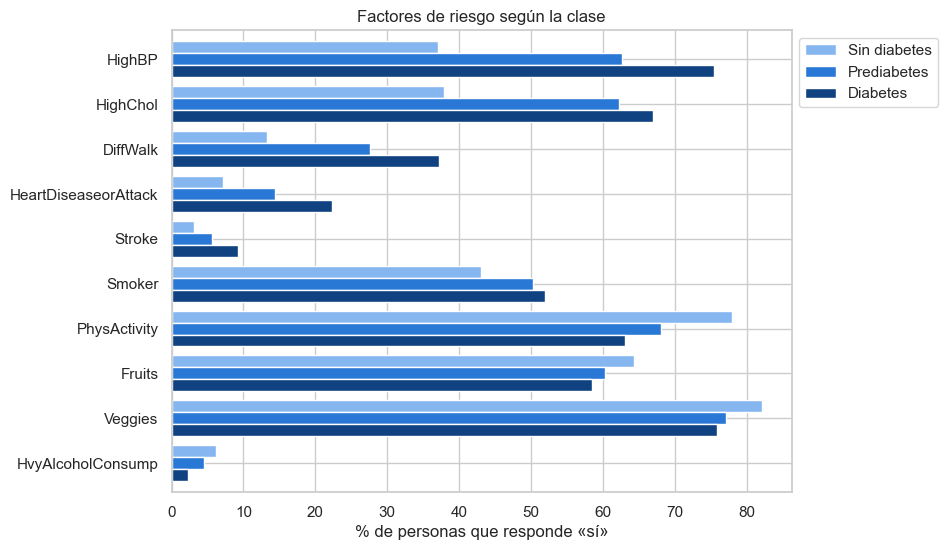

Diabetes_012,Sin diabetes,Prediabetes,Diabetes
HighBP,37.1,62.7,75.4
HighChol,37.9,62.2,67.0
DiffWalk,13.3,27.6,37.2
HeartDiseaseorAttack,7.2,14.3,22.3
Stroke,3.2,5.6,9.2
Smoker,43.0,50.2,51.9
PhysActivity,77.9,68.1,63.1
Fruits,64.3,60.2,58.5
Veggies,82.1,77.1,75.8
HvyAlcoholConsump,6.1,4.5,2.3


In [13]:
binarias = ["HighBP", "HighChol", "DiffWalk", "HeartDiseaseorAttack", "Stroke",
            "Smoker", "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump"]
prevalencia = (train.groupby(OBJETIVO)[binarias].mean() * 100).T.rename(columns=NOMBRES_CLASE)

prevalencia.plot.barh(figsize=(8, 6), color=COLORES, width=0.8)
plt.xlabel("% de personas que responde «sí»")
plt.title("Factores de riesgo según la clase")
plt.legend(title=None, bbox_to_anchor=(1, 1), loc="upper left")
plt.gca().invert_yaxis()
plt.show()

prevalencia.round(1)

**Qué muestra:** el porcentaje de personas de cada clase que tiene cada factor.

**Patrón:**
- La presión alta, el colesterol alto, la dificultad para caminar y las enfermedades del corazón son mucho más comunes en personas con diabetes. Por ejemplo, el 75% de las personas con diabetes tiene presión alta, frente al 37% de las personas sin diabetes.
- La actividad física, las frutas y las verduras son más comunes en personas sin diabetes.
- La prediabetes casi siempre queda en medio, más cerca de la diabetes. Esto hará que sea la clase más difícil de predecir.

**Decisión:** además del F1 macro, revisaremos el recall por clase y la matriz de confusión para ver cuánto confunde el modelo la prediabetes con las otras clases.

### Resumen de decisiones

| Hallazgo | Decisión |
|---|---|
| Columnas en `float64` con valores enteros | Convertir a `int` |
| Sin valores faltantes | No imputar |
| Duplicados (personas con respuestas iguales) | Conservarlos |
| Clases desbalanceadas (84% / 2% / 14%) | F1 macro, `class_weight="balanced"`, división estratificada |
| Outliers en IMC | Conservarlos; escalar para la regresión logística |
| Ninguna variable sola predice la clase | Usar las 21 variables |
| Variables ordinales | Dejarlas como números, sin one-hot |

In [14]:
predictoras = [c for c in df.columns if c != OBJETIVO]
X_train, y_train = train[predictoras], train[OBJETIVO]
X_test, y_test = test[predictoras], test[OBJETIVO]
print(f"X_train: {X_train.shape}   X_test: {X_test.shape}")

X_train: (202944, 21)   X_test: (50736, 21)
